In [67]:
import sys
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyogrio
import numpy as np

print("Python do notebook:", sys.executable)
print("Pandas:", pd.__version__)
print("GeoPandas:", gpd.__version__)

Python do notebook: /home/jz/PM/.venv/bin/python
Pandas: 3.0.6
GeoPandas: 1.2.0


In [ ]:
# Caminhos válidos ao executar pela raiz do projeto ou por src/.
raiz_projeto = Path.cwd()
if raiz_projeto.name == "src":
    raiz_projeto = raiz_projeto.parent

# Altere o código e reinicie o kernel para analisar outro município.
# Lavras: 3138203 | São Paulo: 3550308 | Brasília/DF: 5300108.
arquivo = raiz_projeto / "data" / "BR_setores_CD2022.gpkg"
camada = "BR_setores_CD2022"
codigo_municipio = "3138203"

# Caracterização dos dados.
limite_paineis_externos = 4

# Os gráficos principais são área, densidade e mapa de densidade.
exibir_figuras_apoio = True

In [69]:
print("Arquivo encontrado:", arquivo.exists())
pyogrio.list_layers(arquivo)

Arquivo encontrado: True


array([['BR_setores_CD2022', 'Polygon']], dtype=object)

In [70]:
# Carregamos somente o município escolhido e os atributos usados na análise.
colunas = [
    "CD_SETOR", "CD_MUN", "NM_MUN", "CD_UF", "NM_UF",
    "SITUACAO", "CD_SIT", "CD_TIPO", "AREA_KM2", "v0001",
]
registros = gpd.read_file(
    arquivo, layer=camada, engine="pyogrio", columns=colunas,
    where=f"CD_MUN = '{codigo_municipio}'",
)

if registros.empty:
    raise ValueError("Código não encontrado no arquivo.")
print("Registros geométricos:", len(registros))
registros.head()

Registros geométricos: 219


,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_UF,NM_UF,CD_MUN,NM_MUN,v0001,geometry
0,313820305000001,Urbana,1,0,0.067212,31,Minas Gerais,3138203,Lavras,404,"POLYGON ((-44.99991 -21.24063, -44.99939 -21.2..."
1,313820305000002,Urbana,1,0,0.064010,31,Minas Gerais,3138203,Lavras,478,"POLYGON ((-45.00228 -21.24013, -45.0018 -21.24..."
2,313820305000004,Urbana,1,0,0.195098,31,Minas Gerais,3138203,Lavras,543,"POLYGON ((-45.00212 -21.23415, -45.00103 -21.2..."
3,313820305000005,Urbana,1,0,0.051211,31,Minas Gerais,3138203,Lavras,262,"POLYGON ((-44.99726 -21.23535, -44.99725 -21.2..."
4,313820305000006,Urbana,1,0,0.040538,31,Minas Gerais,3138203,Lavras,92,"POLYGON ((-44.99791 -21.23894, -44.99792 -21.2..."


In [ ]:
# Os arquivos de saída são separados por código, sem sobrescrever outros casos.
nome_municipio = registros["NM_MUN"].iloc[0]
nome_uf = registros["NM_UF"].iloc[0]
rotulo = f"{nome_municipio} — {nome_uf}"
pasta_outputs = raiz_projeto / "outputs" / codigo_municipio
pasta_outputs.mkdir(parents=True, exist_ok=True)

print("Recorte:", rotulo)
print("Pasta das figuras:", pasta_outputs.resolve())

In [72]:
# Contamos os registros repetidos antes de reunir as partes geométricas.
print("Registros originais:", len(registros))
print("Setores distintos:", registros["CD_SETOR"].nunique())
print("Repetições a reunir:", registros["CD_SETOR"].duplicated().sum())

Registros originais: 219
Setores distintos: 219
Repetições a reunir: 0


In [73]:
# Conferir se as partes repetem os mesmos atributos antes de reuni-las.
atributos = registros[colunas].drop_duplicates()
conflitos = atributos.loc[atributos["CD_SETOR"].duplicated(keep=False)]

print("Setores com atributos conflitantes:", conflitos["CD_SETOR"].nunique())
if not conflitos.empty:
    raise ValueError("Investigue os atributos conflitantes antes de continuar.")
if registros["CD_SETOR"].fillna("").str.strip().eq("").any():
    raise ValueError("Existem setores sem código; investigar antes de reunir partes.")


Setores com atributos conflitantes: 0


In [74]:
# A união preserva todas as partes. População e área são mantidas uma vez.
# Não sera somado os atributos repetidos e não sera descartado partes geométricas.
if registros["CD_SETOR"].duplicated().any():
    if not registros.geometry.is_valid.all():
        raise ValueError("Revisar geometrias inválidas antes de reunir as partes.")
    setores = registros.dissolve(by="CD_SETOR", aggfunc="first", as_index=False)
else:
    setores = registros.copy()

setores = setores.sort_values("CD_SETOR").reset_index(drop=True)
print("Setores após reunir as partes:", len(setores))

Setores após reunir as partes: 219


In [75]:
# v0001 é o total de pessoas do setor.
setores["populacao"] = setores["v0001"]


# A densidade é descritiva. Não substitui a demanda populacional.
setores["densidade_hab_km2"] = setores["populacao"] / setores["AREA_KM2"].where(setores["AREA_KM2"].gt(0))

setores[
    ["CD_SETOR", "NM_MUN", "NM_UF", "SITUACAO", "CD_SIT", "AREA_KM2", "populacao"]
].head(10)

,CD_SETOR,NM_MUN,NM_UF,SITUACAO,CD_SIT,AREA_KM2,populacao
0,313820305000001,Lavras,Minas Gerais,Urbana,1,0.067212,404
1,313820305000002,Lavras,Minas Gerais,Urbana,1,0.064010,478
2,313820305000004,Lavras,Minas Gerais,Urbana,1,0.195098,543
3,313820305000005,Lavras,Minas Gerais,Urbana,1,0.051211,262
4,313820305000006,Lavras,Minas Gerais,Urbana,1,0.040538,92
5,313820305000007,Lavras,Minas Gerais,Urbana,1,0.063668,487
6,313820305000008,Lavras,Minas Gerais,Urbana,1,0.081352,280
7,313820305000009,Lavras,Minas Gerais,Urbana,1,0.087165,436
8,313820305000010,Lavras,Minas Gerais,Urbana,1,0.054574,270
9,313820305000011,Lavras,Minas Gerais,Urbana,1,0.062054,289


In [76]:
# Antes de analisar o território, é importante verificar os identificadores.
qualidade_codigos = pd.Series({
    "Códigos ausentes": setores["CD_SETOR"].fillna("").str.strip().eq("").sum(),
    "Códigos repetidos além da primeira ocorrência": setores["CD_SETOR"].duplicated().sum(),
})

In [77]:
# Geometrias ausentes, vazias e inválidas são problemas diferentes.
geometrias_invalidas = (
    setores.geometry.notna()
    & ~setores.geometry.is_empty
    & ~setores.geometry.is_valid
)

qualidade_geometrias = pd.Series({
    "Geometrias ausentes": setores.geometry.isna().sum(),
    "Geometrias vazias": setores.geometry.is_empty.sum(),
    "Geometrias presentes, mas inválidas": geometrias_invalidas.sum(),
})

In [78]:
# Área positiva é necessária para calcular a densidade.
# População zero é registrada, mas não significa automaticamente erro.
qualidade_atributos = pd.Series({
    "Áreas ausentes": setores["AREA_KM2"].isna().sum(),
    "Áreas não positivas": setores["AREA_KM2"].le(0).sum(),
    "Populações ausentes": setores["populacao"].isna().sum(),
    "Populações negativas": setores["populacao"].lt(0).sum(),
    "Populações não inteiras": setores["populacao"].dropna().mod(1).ne(0).sum(),
})

In [79]:
resumo_qualidade = pd.concat({
    "Códigos": qualidade_codigos,
    "Geometrias": qualidade_geometrias,
    "Atributos": qualidade_atributos,
}).rename("ocorrencias").to_frame()

resumo_qualidade

ocorrencias
Códigos    Códigos ausentes                                         0
           Códigos repetidos além da primeira ocorrência            0
Geometrias Geometrias ausentes                                      0
           Geometrias vazias                                        0
           Geometrias presentes, mas inválidas                      0
Atributos  Áreas ausentes                                           0
           Áreas não positivas                                      0
           Populações ausentes                                      0
           Populações negativas                                     0
           Populações não inteiras                                  0

In [80]:
# Identificar setores inválidos para documentar a pendência, sem alterá-los.
setores_invalidos = setores.loc[
    geometrias_invalidas,
    ["CD_SETOR", "CD_SIT", "CD_TIPO", "populacao"],
]

if not setores_invalidos.empty:
    print("Geometrias inválidas: revisar antes da modelagem. Setores mantidos.")
    display(setores_invalidos)


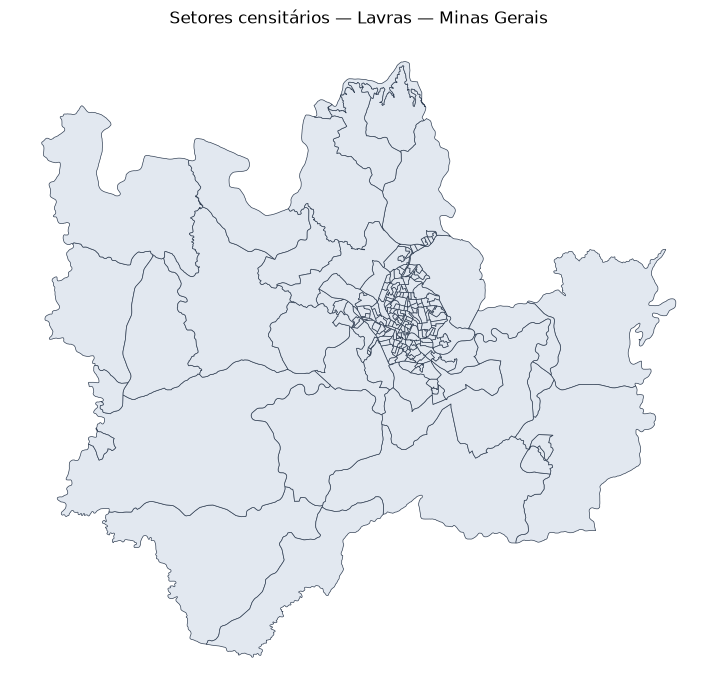

In [81]:
# Figuras de apoio: ative exibir_figuras_apoio na configuração.
if exibir_figuras_apoio:
    # O primeiro mapa mostra os polígonos, antes de escolher um ponto por setor.
    # Geometrias válidas não comprovam precisão nem ausência de sobreposições.
    fig, ax = plt.subplots(figsize=(9, 9))

    setores.plot(
        ax=ax,
        facecolor="#e2e8f0",
        edgecolor="#334155",
        linewidth=0.5,
    )

    ax.set_title(f"Setores censitários — {rotulo}")
    ax.set_axis_off()
    fig.savefig(pasta_outputs / "municipio_mapa_setores_censitarios.svg", dpi=300, bbox_inches="tight")
    plt.show()

In [82]:
# Contar urbanos e rurais, sem ocultar a situação ausente.
setores["SITUACAO"].value_counts(dropna=False)

SITUACAO
Urbana    189
Rural      29
NaN         1
Name: count, dtype: int64

In [83]:
# Inspecionamos registros sem situação textual antes de classificá-los.
sem_situacao = setores.loc[
    setores["SITUACAO"].isna(),
    ["CD_SETOR", "CD_SIT", "CD_TIPO", "NM_MUN", "AREA_KM2", "populacao"],
]

sem_situacao

,CD_SETOR,CD_SIT,CD_TIPO,NM_MUN,AREA_KM2,populacao
199,313820305000223,9,0,Lavras,2.39357,0


In [ ]:
# O dicionário define os códigos. CD_SITUACAO corresponde a CD_SIT na malha.
dicionario = pd.read_excel(raiz_projeto / "data" / "Dicionario_de_dados_malha_agregados.xlsx")
dicionario.columns = ["variavel", "codigo", "descricao"]
dicionario["variavel"] = dicionario["variavel"].ffill()
dicionario["codigo"] = (
    dicionario["codigo"].astype("string").str.replace(r"\.0$", "", regex=True).str.strip()
)

In [85]:
# Obtemos as descrições sem fixar posições de linhas do dicionário.
mapa_situacao = dicionario.loc[
    dicionario["variavel"].eq("CD_SITUACAO") & dicionario["codigo"].notna()
].set_index("codigo")["descricao"]

mapa_tipo = dicionario.loc[
    dicionario["variavel"].eq("CD_TIPO") & dicionario["codigo"].notna()
].set_index("codigo")["descricao"]

In [86]:
setores["descricao_situacao"] = setores["CD_SIT"].map(mapa_situacao).fillna("Código ausente ou não descrito")
setores["descricao_tipo"] = setores["CD_TIPO"].map(mapa_tipo).fillna("Código ausente ou não descrito")

codigos_nao_descritos = pd.Series({
    "CD_SIT": setores.loc[~setores["CD_SIT"].isin(mapa_situacao.index), "CD_SIT"].unique().tolist(),
    "CD_TIPO": setores.loc[~setores["CD_TIPO"].isin(mapa_tipo.index), "CD_TIPO"].unique().tolist(),
})

codigos_nao_descritos

CD_SIT     []
CD_TIPO    []
dtype: object

In [87]:
# Código 9 significa massas de água.
setores["situacao_analise"] = setores["SITUACAO"].copy()

setores.loc[
    setores["CD_SIT"].eq("9"),
    "situacao_analise",
] = "Massas de água"

setores["situacao_analise"].value_counts(dropna=False)

situacao_analise
Urbana            189
Rural              29
Massas de água      1
Name: count, dtype: int64

In [88]:
# Inspecionar todos os setores de população zero, sem removê-los automaticamente.
setores.loc[
    setores["populacao"].eq(0),
    ["CD_SETOR", "situacao_analise", "AREA_KM2", "populacao"],
]

,CD_SETOR,situacao_analise,AREA_KM2,populacao
199,313820305000223,Massas de água,2.39357,0


In [89]:
# Comparar os setores urbanos/rurais e mantemos os de população zero.
setores_analise = setores.loc[
    setores["situacao_analise"].isin(["Urbana", "Rural"])
].copy()

print("Setores urbanos e rurais:", len(setores_analise))
if setores_analise.empty:
    raise ValueError("O recorte não possui setores urbanos/rurais.")

Setores urbanos e rurais: 218


In [90]:
# Primeiro, descrever a extensão dos setores usando a área do IBGE.
resumo_areas = (
    setores_analise
    .groupby("situacao_analise")["AREA_KM2"]
    .agg(
        quantidade="count",
        area_total_km2="sum",
        media_km2="mean",
        mediana_km2="median",
        menor_km2="min",
        maior_km2="max",
    )
)

resumo_areas.round(3)

,quantidade,area_total_km2,media_km2,mediana_km2,menor_km2,maior_km2
situacao_analise,,,,,,
Rural,29,510.625,17.608,15.033,0.333,65.943
Urbana,189,51.725,0.274,0.086,0.001,11.486


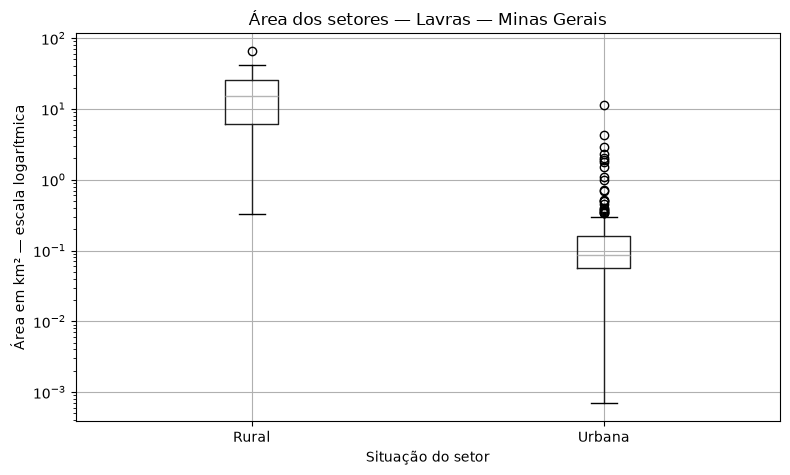

In [91]:
# A escala logarítmica torna visíveis as diferenças de tamanho.
# A média urbana acima da mediana sugere setores grandes que merecem inspeção.
fig, ax = plt.subplots(figsize=(8, 5))

dados_positivos = setores_analise.loc[setores_analise["AREA_KM2"].gt(0)]

dados_positivos.boxplot(
    column="AREA_KM2",
    by="situacao_analise",
    ax=ax,
    showfliers=True,
)

ax.set_yscale("log")
ax.set_title(f"Área dos setores — {rotulo}")
ax.set_xlabel("Situação do setor")
ax.set_ylabel("Área em km² — escala logarítmica")
fig.suptitle("")
plt.tight_layout()
fig.savefig(pasta_outputs / "boxplot_area_urbana_rural.svg", dpi=300, bbox_inches="tight")
plt.show()


In [92]:
# Inspecionar os cinco maiores setores urbanos. Valor extremo não é erro.
urbanos = setores_analise.loc[
    setores_analise["situacao_analise"].eq("Urbana")
].copy()

urbanos[
    ["CD_SETOR", "CD_SIT", "AREA_KM2", "populacao"]
].nlargest(5, "AREA_KM2")


,CD_SETOR,CD_SIT,AREA_KM2,populacao
158,313820305000171,2,11.486080,725
102,313820305000106,2,4.245691,1016
216,313820305000241,2,2.905007,71
210,313820305000234,2,2.317213,265
167,313820305000180,2,2.003408,660


In [93]:
# Agora incorporar a população: área maior não significa demanda maior.
resumo_populacao = (
    setores_analise
    .groupby("situacao_analise")["populacao"]
    .agg(
        populacao_total="sum",
        media_por_setor="mean",
        mediana_por_setor="median",
        menor_por_setor="min",
        maior_por_setor="max",
    )
)

resumo_populacao.round(2)

,populacao_total,media_por_setor,mediana_por_setor,menor_por_setor,maior_por_setor
situacao_analise,,,,,
Rural,4584,158.07,140.0,22,375
Urbana,100177,530.04,497.0,40,1528


In [94]:
# Comparar participação no território e na população, separadamente.
participacao = pd.DataFrame(index=resumo_areas.index)

participacao["area_percentual"] = (
    100 * resumo_areas["area_total_km2"] / resumo_areas["area_total_km2"].sum()
)
participacao["populacao_percentual"] = (
    100 * resumo_populacao["populacao_total"] / resumo_populacao["populacao_total"].sum()
)

participacao.round(2)

,area_percentual,populacao_percentual
situacao_analise,,
Rural,90.8,4.38
Urbana,9.2,95.62


In [95]:
# Densidade média do setor = população / área fornecida pelo IBGE.
# Ela não identifica quais partes do setor concentram moradores.
setores_analise["densidade_hab_km2"] = (
    setores_analise["populacao"]
    / setores_analise["AREA_KM2"].where(setores_analise["AREA_KM2"].gt(0))
)

setores_analise[
    ["CD_SETOR", "populacao", "AREA_KM2", "densidade_hab_km2"]
].head().round(2)

,CD_SETOR,populacao,AREA_KM2,densidade_hab_km2
0,313820305000001,404,0.07,6010.86
1,313820305000002,478,0.06,7467.56
2,313820305000004,543,0.20,2783.21
3,313820305000005,262,0.05,5116.08
4,313820305000006,92,0.04,2269.46


In [96]:
# Descrever a distribuição das densidades entre os setores de cada grupo.
resumo_densidades = (
    setores_analise
    .groupby("situacao_analise")["densidade_hab_km2"]
    .agg(
        mediana="median",
        menor="min",
        maior="max",
    )
)

resumo_densidades.round(2)

,mediana,menor,maior
situacao_analise,,,
Rural,10.32,2.61,345.47
Urbana,5679.85,24.44,198237.54


In [97]:
# Densidade do grupo usa totais, não a média simples das densidades dos setores.
# Essa medida é diferente da mediana de um setor típico.
densidade_grupos = (
    resumo_populacao["populacao_total"]
    / resumo_areas["area_total_km2"]
)

densidade_grupos.rename("densidade_do_grupo_hab_km2").round(2)

situacao_analise
Rural        8.98
Urbana    1936.72
Name: densidade_do_grupo_hab_km2, dtype: float64

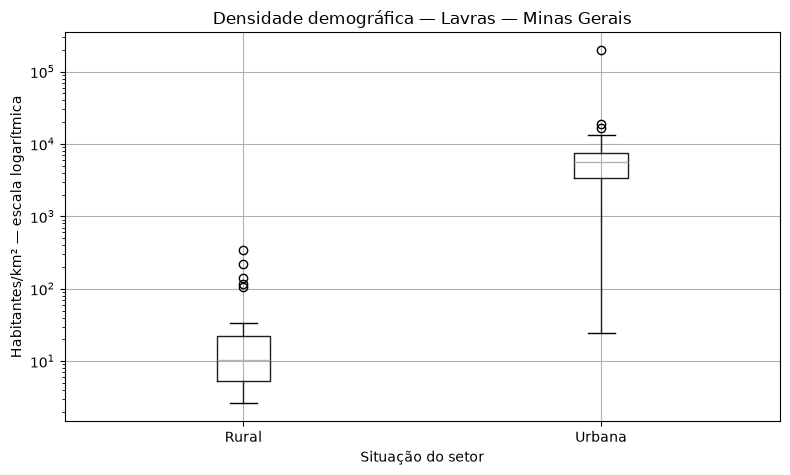

In [98]:
# Valores zero permanecem nos dados, mas não aparecem no boxplot logarítmico.
fig, ax = plt.subplots(figsize=(8, 5))

dados_positivos = setores_analise.loc[setores_analise["densidade_hab_km2"].gt(0)]

dados_positivos.boxplot(
    column="densidade_hab_km2",
    by="situacao_analise",
    ax=ax,
    showfliers=True,
)

ax.set_yscale("log")
ax.set_title(f"Densidade demográfica — {rotulo}")
ax.set_xlabel("Situação do setor")
ax.set_ylabel("Habitantes/km² — escala logarítmica")
fig.suptitle("")
plt.tight_layout()
# Exportamos em SVG para preservar os elementos vetoriais.
fig.savefig(pasta_outputs / "boxplot_densidade_urbana_rural.svg", dpi=300, bbox_inches="tight")
plt.show()


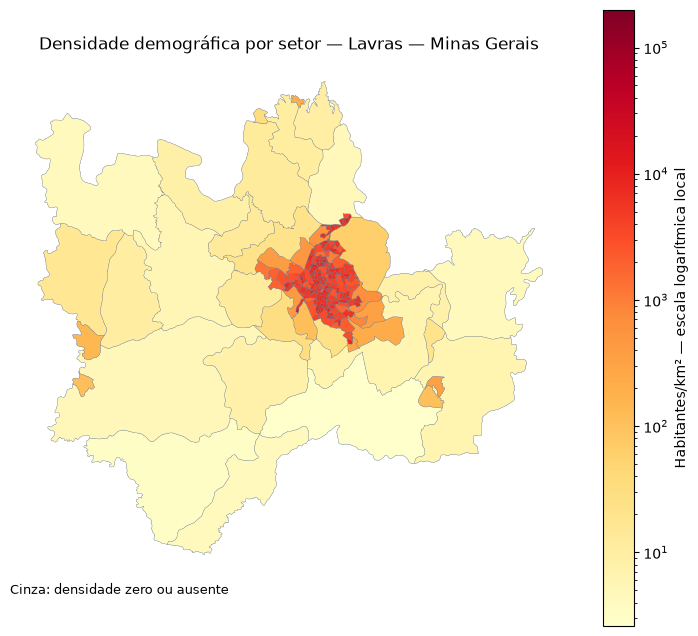

In [99]:
# Setores com densidade zero/ausente ficam cinza. Positivos usam escala logarítmica.
from matplotlib.colors import LogNorm

positivos = setores_analise.loc[setores_analise["densidade_hab_km2"].gt(0)]
fig, ax = plt.subplots(figsize=(9, 8))
setores_analise.plot(ax=ax, color="#e2e8f0", edgecolor="#64748b", linewidth=0.2)

if not positivos.empty:
    # Cada município usa sua própria escala; cores não são diretamente comparáveis.
    minimo = positivos["densidade_hab_km2"].min()
    maximo = positivos["densidade_hab_km2"].max()
    positivos.plot(
        column="densidade_hab_km2", cmap="YlOrRd",
        norm=LogNorm(vmin=minimo, vmax=max(maximo, minimo * 1.01)),
        legend=True, edgecolor="#64748b", linewidth=0.2, ax=ax,
        legend_kwds={"label": "Habitantes/km² — escala logarítmica local"},
    )

ax.set_title(f"Densidade demográfica por setor — {rotulo}")
ax.set_axis_off()
ax.text(0, -0.03, "Cinza: densidade zero ou ausente", transform=ax.transAxes, fontsize=9)
fig.savefig(pasta_outputs / "mapa_densidade_demografica.svg", bbox_inches="tight")
plt.show()


In [100]:
# CD_SIT: situação territorial detalhada de todos os setores, incluindo água.
resumo_situacao = setores.groupby(
    ["CD_SIT", "descricao_situacao"], dropna=False
).agg(
    setores=("CD_SETOR", "count"),
    populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    area_mediana_km2=("AREA_KM2", "median"),
    densidade_mediana_hab_km2=("densidade_hab_km2", "median"),
)

In [101]:
# Participação e densidade agregada têm denominadores explícitos.
resumo_situacao["populacao_percentual"] = 100 * resumo_situacao["populacao"] / setores["populacao"].sum()
resumo_situacao["densidade_grupo_hab_km2"] = resumo_situacao["populacao"] / resumo_situacao["area_km2"]

resumo_situacao.round(2)

,,setores,populacao,area_km2,area_mediana_km2,densidade_mediana_hab_km2,populacao_percentual,densidade_grupo_hab_km2
CD_SIT,descricao_situacao,,,,,,,
1,Área urbana de alta densidade de edificações de cidade ou vila,179,93675,21.50,0.08,6010.86,89.42,4356.46
2,Área urbana de baixa densidade de edificações de cidade ou vila,10,6502,30.22,1.96,365.29,6.21,215.14
5,Aglomerado rural - Povoado,4,846,4.84,0.96,180.69,0.81,174.65
6,Aglomerado rural - Núcleo rural,1,152,1.45,1.45,104.57,0.15,104.57
7,Aglomerado rural - Lugarejo,1,22,0.65,0.65,33.77,0.02,33.77
8,Área rural (exclusive aglomerados),23,3564,503.68,19.18,8.02,3.40,7.08
9,Massas de água,1,0,2.39,2.39,0.00,0.00,0.00


In [102]:
# CD_TIPO: perfil de ocupação dos setores urbanos e rurais, mantendo institucionais.
# Categorias com poucos setores precisam ser interpretadas com cuidado.
resumo_tipos = setores_analise.groupby(
    ["CD_TIPO", "descricao_tipo"], dropna=False
).agg(
    setores=("CD_SETOR", "count"),
    populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    populacao_mediana_setor=("populacao", "median"),
    densidade_mediana_hab_km2=("densidade_hab_km2", "median"),
)

In [103]:
resumo_tipos["populacao_percentual"] = 100 * resumo_tipos["populacao"] / setores_analise["populacao"].sum()

resumo_tipos.round(2)

,,setores,populacao,area_km2,populacao_mediana_setor,densidade_mediana_hab_km2,populacao_percentual
CD_TIPO,descricao_tipo,,,,,,
0,Não especial,214,104372,560.87,470.5,5104.92,99.63
6,Unidade prisional,1,137,0.00,137.0,198237.54,0.13
7,Convento / hospital / ILPI / IACA,3,252,1.48,60.0,2964.84,0.24


In [104]:
# Para centroides e distâncias, transformei as coordenadas para metros.
# A densidade permanece calculada com AREA_KM2 do IBGE.
crs_metrico = setores.estimate_utm_crs()

print("Sistema projetado sugerido:", crs_metrico)
# Em municípios muito extensos, avaliar a distorção da projeção local.

Sistema projetado sugerido: EPSG:32723


In [105]:
municipio_m = setores.to_crs(crs_metrico)

print("Unidades dos eixos:")
for eixo in municipio_m.crs.axis_info:
    print(eixo.name, "—", eixo.unit_name)

Unidades dos eixos:
Easting — metre
Northing — metre


In [106]:
# Comparamos a área projetada com a área fornecida, sem substituir o atributo.
municipio_m["area_calculada_km2"] = municipio_m.geometry.area / 1_000_000

comparacao = municipio_m[
    ["CD_SETOR", "AREA_KM2", "area_calculada_km2"]
].copy()

comparacao.head()

,CD_SETOR,AREA_KM2,area_calculada_km2
0,313820305000001,0.067212,0.067158
1,313820305000002,0.064010,0.063959
2,313820305000004,0.195098,0.194942
3,313820305000005,0.051211,0.051170
4,313820305000006,0.040538,0.040506


In [107]:
# A diferença relativa é uma comparação de medidas, não uma prova de erro.
comparacao["diferenca_percentual"] = (
    100
    * (comparacao["area_calculada_km2"] - comparacao["AREA_KM2"])
    / comparacao["AREA_KM2"].where(comparacao["AREA_KM2"] > 0)
)

comparacao["diferenca_percentual"].describe()

count    219.000000
mean      -0.079957
std        0.000094
min       -0.080098
25%       -0.079986
50%       -0.079979
75%       -0.079967
max       -0.079359
Name: diferenca_percentual, dtype: float64

In [108]:
# Projetar o recorte de análise, preservando população e densidade.
setores_m = setores_analise.to_crs(crs_metrico)

print("Setores para representação da demanda:", len(setores_m))

Setores para representação da demanda: 218


In [109]:
# O centroide é o centro geométrico de área, não o centro da população.
# Estes pontos são calculados aqui a partir dos polígonos do IBGE.
centroides = setores_m.geometry.centroid

centroides.head()

0    POINT (499975.542 7651035.466)
1     POINT (499812.76 7651091.474)
2     POINT (499876.308 7651728.14)
3     POINT (500262.134 7651634.14)
4    POINT (500118.752 7651315.477)
dtype: geometry

In [110]:
# A forma do polígono pode fazer o centroide ficar fora do próprio setor.
centroide_coberto = setores_m.geometry.covers(centroides)
fora = ~centroide_coberto

print("Setores analisados:", len(setores_m))
print("Centroides fora do próprio setor:", fora.sum())

proporcao_centroides_externos = 100 * fora.sum() / len(setores_m)
print(f"Proporção de centroides externos: {proporcao_centroides_externos:.2f}%")

Setores analisados: 218
Centroides fora do próprio setor: 4
Proporção de centroides externos: 1.83%


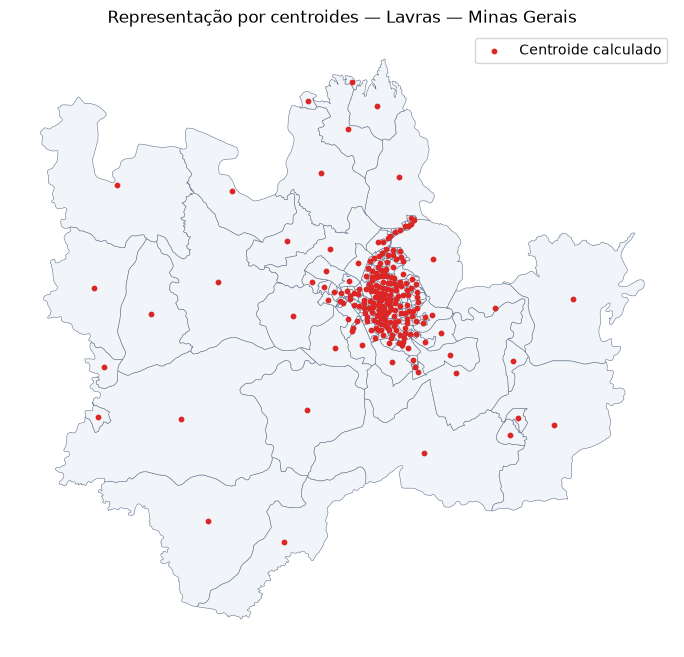

In [111]:
# Figuras de apoio: ative exibir_figuras_apoio na configuração.
if exibir_figuras_apoio:
    # Mantemos somente o centroide vermelho como representação.
    fig, ax = plt.subplots(figsize=(10, 8))

    setores_m.plot(
        ax=ax,
        facecolor="#f1f5f9",
        edgecolor="#64748b",
        linewidth=0.4,
    )
    centroides.plot(
        ax=ax,
        color="#dc2626",
        markersize=10,
        label="Centroide calculado",
    )

    ax.set_title(f"Representação por centroides — {rotulo}")
    ax.legend()
    ax.set_axis_off()
    # Exportamos em SVG para preservar os elementos vetoriais.
    fig.savefig(pasta_outputs / "municipio_mapa_centroides.svg", dpi=300, bbox_inches="tight")
    plt.show()


In [112]:
# Identificar os casos externos e a população representada por cada ponto.
diagnostico = setores_m.loc[
    fora,
    ["CD_SETOR", "situacao_analise", "CD_SIT", "AREA_KM2", "populacao"],
].copy()

diagnostico

,CD_SETOR,situacao_analise,CD_SIT,AREA_KM2,populacao
0,313820305000001,Urbana,1,0.067212,404
72,313820305000075,Urbana,1,0.164331,705
78,313820305000081,Urbana,1,0.134871,724
176,313820305000189,Urbana,1,0.096278,642


In [113]:
# Para um ponto externo, esta é a distância até o ponto mais próximo do setor.
diagnostico["distancia_ao_setor_m"] = (
    centroides.loc[fora].distance(setores_m.geometry.loc[fora])
)

diagnostico.round(2)

,CD_SETOR,situacao_analise,CD_SIT,AREA_KM2,populacao,distancia_ao_setor_m
0,313820305000001,Urbana,1,0.07,404,14.23
72,313820305000075,Urbana,1,0.16,705,178.65
78,313820305000081,Urbana,1,0.13,724,10.66
176,313820305000189,Urbana,1,0.10,642,21.93


Casos externos: 4 | Painéis exibidos: 4


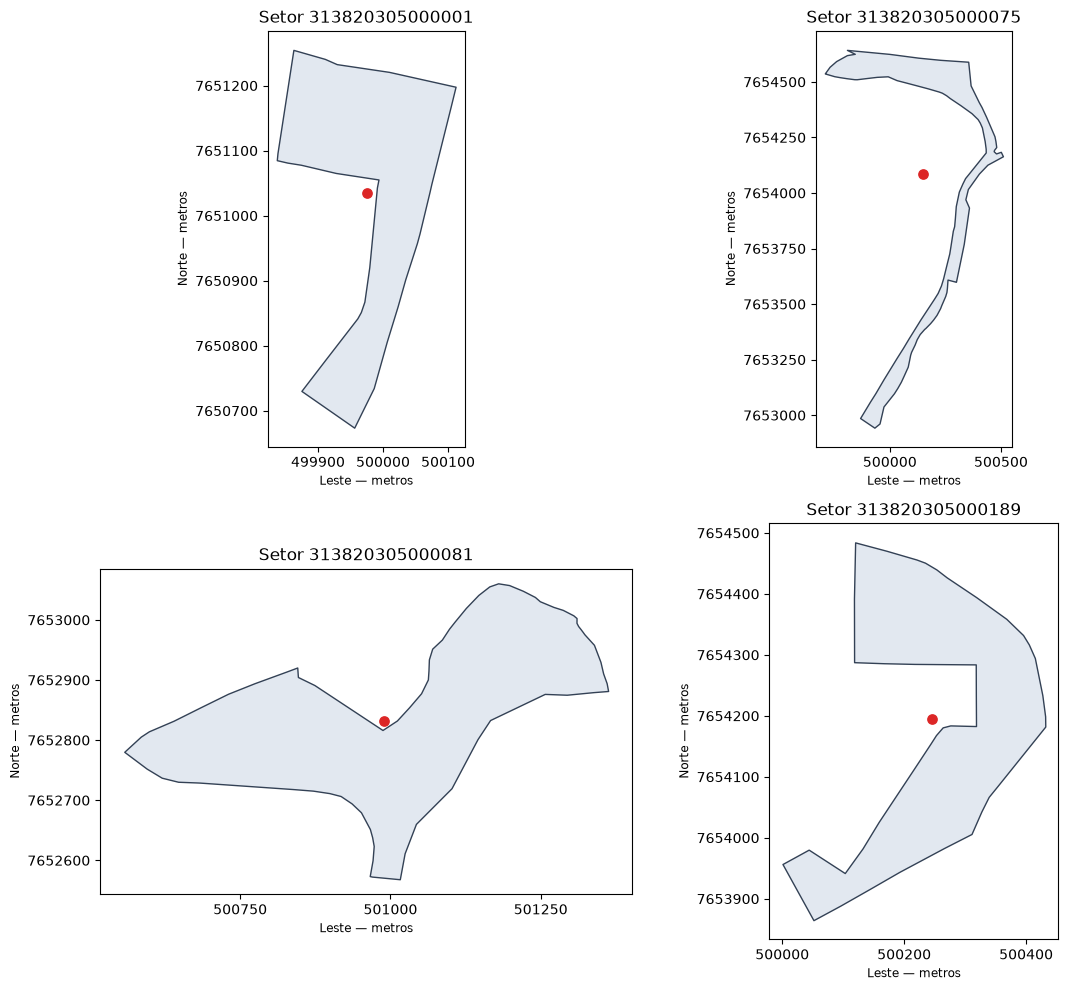

In [114]:
# Figuras de apoio: ative exibir_figuras_apoio na configuração.
if exibir_figuras_apoio:
    # Limitados apenas os painéis, não os setores mantidos na análise.
    casos_plot = diagnostico.head(limite_paineis_externos)
    quantidade = len(casos_plot)
    print("Casos externos:", len(diagnostico), "| Painéis exibidos:", quantidade)

    if quantidade > 0:
        linhas = (quantidade + 1) // 2
        fig, axes = plt.subplots(linhas, 2, figsize=(12, 5 * linhas), squeeze=False)

        for ax, idx in zip(axes.flat, casos_plot.index):
            setor = setores_m.loc[[idx]]
            setor.plot(ax=ax, facecolor="#e2e8f0", edgecolor="#334155")
            centroides.loc[[idx]].plot(ax=ax, color="#dc2626", markersize=45)
            ax.set_title(f"Setor {setor['CD_SETOR'].iloc[0]}")
            ax.set_xlabel("Leste — metros")
            ax.set_ylabel("Norte — metros")
            ax.set_aspect("equal")
            ax.ticklabel_format(style="plain", useOffset=False)
            ax.locator_params(axis="x", nbins=3)

        for ax in axes.flat[quantidade:]:
            ax.set_visible(False)

        plt.tight_layout()
        fig.savefig(pasta_outputs / "diagnostico_centroides_externos.svg", dpi=300, bbox_inches="tight")
        plt.show()

In [115]:
# Cada centroide é um local onde o modelo poderá abrir uma instalação.
candidatos = gpd.GeoDataFrame(
    {"CD_CANDIDATO": setores_m["CD_SETOR"]},
    geometry=centroides,
    crs=setores_m.crs,
)

print("Quantidade de candidatos:", len(candidatos))
candidatos.head()

Quantidade de candidatos: 218


,CD_CANDIDATO,geometry
0,313820305000001,POINT (499975.542 7651035.466)
1,313820305000002,POINT (499812.76 7651091.474)
2,313820305000004,POINT (499876.308 7651728.14)
3,313820305000005,POINT (500262.134 7651634.14)
4,313820305000006,POINT (500118.752 7651315.477)


In [116]:
# Escolhido o primeiro setor como origem.
codigo_origem = setores_m["CD_SETOR"].iloc[0]
ponto_origem = centroides.iloc[0]

# O sistema projetado fornece distâncias em metros.
distancias_origem = candidatos.geometry.distance(ponto_origem) / 1_000

distancias_origem.index = candidatos["CD_CANDIDATO"]
distancias_origem.name = "distancia_km"

print("Setor de origem:", codigo_origem)
distancias_origem.sort_values().head(10)

Setor de origem: 313820305000001


CD_CANDIDATO
313820305000001    0.000000
313820305000002    0.172148
313820305000150    0.200385
313820305000008    0.277062
313820305000131    0.286890
313820305000006    0.314507
313820305000231    0.339122
313820305000019    0.365025
313820305000016    0.380298
313820305000010    0.399971
Name: distancia_km, dtype: float64

In [117]:
# Verificado somente a linha de demonstração, não uma matriz completa.
qualidade_exemplo_distancias = pd.Series({
    "Distâncias calculadas": len(distancias_origem),
    "Valores ausentes": distancias_origem.isna().sum(),
    "Valores não finitos": (~np.isfinite(distancias_origem.to_numpy())).sum(),
    "Valores negativos": distancias_origem.lt(0).sum(),
    "Distância ao próprio candidato é zero": np.isclose(distancias_origem.loc[codigo_origem], 0),
})

qualidade_exemplo_distancias

Distâncias calculadas                     218
Valores ausentes                            0
Valores não finitos                         0
Valores negativos                           0
Distância ao próprio candidato é zero    True
dtype: object

In [118]:
# O tamanho previsto é calculado sem gerar todos os pares de distâncias.
numero_setores = len(setores_m)
numero_candidatos = len(candidatos)
numero_pares = numero_setores * numero_candidatos
memoria_matriz_gib = numero_pares * 8 / 1024 ** 3

print("Pares setor–candidato previstos:", numero_pares)
print(f"Matriz float64: {memoria_matriz_gib:.3f} GiB, sem índices e cópias")

Pares setor–candidato previstos: 47524
Matriz float64: 0.000 GiB, sem índices e cópias


In [119]:
# Síntese: tamanho, demanda e limitações da representação.
resumo_instancia = pd.Series({
    "Código do recorte": codigo_municipio,
    "Nome": nome_municipio,
    "UF": nome_uf,
    "Ano dos dados": 2022,
    "Registros geométricos": len(registros),
    "Setores distintos": len(setores),
    "Setores urbanos e rurais": len(setores_analise),
    "Setores com demanda positiva": setores_analise["populacao"].gt(0).sum(),
    "Locais candidatos": len(candidatos),
    "Pares de distâncias previstos": numero_pares,
    "Distâncias demonstrativas calculadas": len(distancias_origem),
    "População dos setores urbanos e rurais": setores_analise["populacao"].sum(),
    "Centroides externos mantidos": fora.sum(),
    "Centroides externos (%)": round(proporcao_centroides_externos, 2),
})

resumo_instancia


Código do recorte                              3138203
Nome                                            Lavras
UF                                        Minas Gerais
Ano dos dados                                     2022
Registros geométricos                              219
Setores distintos                                  219
Setores urbanos e rurais                           218
Setores com demanda positiva                       218
Locais candidatos                                  218
Pares de distâncias previstos                    47524
Distâncias demonstrativas calculadas               218
População dos setores urbanos e rurais          104761
Centroides externos mantidos                         4
Centroides externos (%)                           1.83
dtype: object

In [120]:
# Tabela municipal: urbano e rural nos mesmos indicadores.
resumo_municipal = pd.DataFrame({
    "setores": resumo_areas["quantidade"],
    "populacao": resumo_populacao["populacao_total"],
    "populacao_percentual": participacao["populacao_percentual"],
    "area_km2": resumo_areas["area_total_km2"],
    "area_percentual": participacao["area_percentual"],
    "densidade_grupo_hab_km2": densidade_grupos,
    "densidade_mediana_setores_hab_km2": resumo_densidades["mediana"],
})

resumo_municipal.round(2)


,setores,populacao,populacao_percentual,area_km2,area_percentual,densidade_grupo_hab_km2,densidade_mediana_setores_hab_km2
situacao_analise,,,,,,,
Rural,29,4584,4.38,510.62,90.8,8.98,10.32
Urbana,189,100177,95.62,51.73,9.2,1936.72,5679.85


In [121]:
# A conclusão reutiliza a tabela de qualidade já apresentada.
problemas_encontrados = resumo_qualidade["ocorrencias"].loc[
    resumo_qualidade["ocorrencias"].gt(0)
]

In [ ]:
# Conclusão municipal baseada nos resultados, sem alegar viabilidade do solver.
print(f"Recorte: {rotulo}. Dados do Censo 2022.")
print(f"São {len(setores_analise):,} setores urbanos e rurais e {len(candidatos):,} candidatos.")
print(f"População: {setores_analise['populacao'].sum():,} pessoas.")
if problemas_encontrados.empty:
    print("Não foram encontrados problemas nas verificações essenciais realizadas.")
else:
    print("Há pendências nas verificações essenciais:")
    print(problemas_encontrados.to_string())
print(f"Centroides externos: {fora.sum()} ({proporcao_centroides_externos:.2f}%), mantidos.")
print("O exemplo de distâncias é referente a custos aproximados de deslocamento.")

Recorte: Lavras — Minas Gerais. Dados do Censo 2022.
São 218 setores urbanos e rurais e 218 candidatos.
População: 104,761 pessoas.
Não foram encontrados problemas nas verificações essenciais realizadas.
Centroides externos: 4 (1.83%), mantidos.
O exemplo de distâncias é referente a custos aproximados de deslocamento.
